##### Boilerplate

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys

PROJECT_DIR = "/content/drive/MyDrive/DumLLM"
NOTEBOOKS_DIR = os.path.join(PROJECT_DIR, "notebooks")
SRC_DIR = os.path.join(PROJECT_DIR, "src")

os.chdir(PROJECT_DIR)

sys.path.insert(0, PROJECT_DIR)
sys.path.insert(0, SRC_DIR)
sys.path.insert(0, NOTEBOOKS_DIR)

print("DumLLM initialized!")
print("Working directory:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DumLLM initialized!
Working directory: /content/drive/MyDrive/DumLLM


In [2]:
import importlib
import sys

importlib.invalidate_caches()

import previous_chapters
import gpt_download

importlib.reload(previous_chapters)
importlib.reload(gpt_download)

print("Modules reloaded!")
print([
    name for name in dir(previous_chapters)
    if not name.startswith("_")
])
print([
    name for name in dir(gpt_download)
    if not name.startswith("_")
])

Modules reloaded!
['DataLoader', 'Dataset', 'FeedForward', 'GELU', 'GPTDatasetV1', 'GPTModel', 'LayerNorm', 'MaxNLocator', 'MultiHeadAttention', 'TransformerBlock', 'assign', 'calc_loss_batch', 'calc_loss_loader', 'create_dataloader_v1', 'evaluate_model', 'generate', 'generate_and_print_sample', 'generate_text_simple', 'load_weights_into_gpt', 'nn', 'np', 'plot_losses', 'plt', 'text_to_token_ids', 'tiktoken', 'token_ids_to_text', 'torch', 'train_model_simple']
['TemporaryDirectory', 'download_and_load_gpt2', 'download_file', 'json', 'load_gpt2_params_from_tf_ckpt', 'np', 'os', 'requests', 'tf', 'tqdm']


# 7. Fine-tuning to follow instructions

In [3]:
from importlib.metadata import version

pkgs = ["matplotlib",  # Plotting library
        "numpy",       # PyTorch & TensorFlow dependency
        "tiktoken",    # Tokenizer
        "torch",       # Deep learning library
        "tensorflow",  # For OpenAI's pretrained weights
        "pandas"       # Dataset loading
       ]
for p in pkgs:
    print(f"{p} version: {version(p)}")

matplotlib version: 3.10.0
numpy version: 2.4.6
tiktoken version: 0.14.0
torch version: 2.14.1+cpu
tensorflow version: 2.21.0
pandas version: 2.2.3


## 7.2 Preparing a dataset for supervised instruction finetuning

In [4]:
import json
import os
import urllib
from pathlib import Path


def load_file(file_path):
  with open(file_path, "rb") as f:
    data = json.loads(f.read().decode())
  return data

file_path = Path("public/instruction-data.json")
data = load_file(file_path)

In [5]:
print("Number of  examples:", len(data))
print(data[50])

Number of  examples: 1100
{'instruction': 'Identify the correct spelling of the following word.', 'input': 'Ocassion', 'output': "The correct spelling is 'Occasion.'"}


In [6]:
def format_input(entry):
  instruction_text = (
      f"Below is an instruction that describes a task. "
      "Write a response that appropriately completes the request.\n\n"
      f"### Instruction:\n{entry['instruction']}"
  )

  input_text = f"\n\n### Input:\n{entry['input']}" if entry['input'] else ""

  return instruction_text + input_text

In [7]:
print(format_input(data[50]))

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Identify the correct spelling of the following word.

### Input:
Ocassion


In [8]:
model_input = format_input(data[999])
desired_response = f"\n\n### Response:\n{data[999]['output']}"

print(model_input + desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
What is an antonym of 'complicated'?

### Response:
An antonym of 'complicated' is 'simple'.


In [9]:
train_portion = int(len(data) * 0.85)
test_portion = int(len(data) * 0.1)
val_potion = len(data) - train_portion - test_portion

train_data = data[:train_portion]
test_data = data[train_portion:train_portion + test_portion]
val_data = data[train_portion + test_portion:]

In [10]:
print("Train data size:", len(train_data))
print("Test data size:", len(test_data))
print("Validation data size:", len(val_data))

Train data size: 935
Test data size: 110
Validation data size: 55


## 7.3 Organinsing data into training batches

In [11]:
import torch
from torch.utils.data import Dataset


class InstructionDataset(Dataset):
    def __init__(self, data, tokenizer):
        self.data = data

        # Pre-tokenize texts
        self.encoded_texts = []
        for entry in data:
            instruction_plus_input = format_input(entry)
            response_text = f"\n\n### Response:\n{entry['output']}"
            full_text = instruction_plus_input + response_text
            self.encoded_texts.append(
                tokenizer.encode(full_text)
            )

    def __getitem__(self, index):
        return self.encoded_texts[index]

    def __len__(self):
        return len(self.data)

In [12]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

In [13]:
def custom_collate_draft_1(batch, pad_token_id=50256, device="cpu"):
  # find the longest squence in the batch
  # increase the max length by +1, which will add one extra padding token below
  batch_max_length = max(len(item) + 1 for item in batch)

  # pad and prepare inputs
  inputs_lst = []

  for item in batch:
    new_item = item.copy()

    # add an <|endoftext|> token
    new_item += [pad_token_id]

    # pad sequences to batch_max_length
    padded = (
        new_item + [pad_token_id] * (batch_max_length - len(new_item))
    )

    # via padded[:-1] we remove the extra padded token
    inputs = torch.tensor(padded[:-1])
    inputs_lst.append(inputs)

  # convert list of inputs to tensor and transfer to target device
  inputs_tensor = torch.stack(inputs_lst).to(device)
  return inputs_tensor

In [14]:
inputs_1 = [0, 1, 2, 3, 4]
inputs_2 = [5, 6]
inputs_3 = [7, 8, 9]

batch = (
    inputs_1,
    inputs_2,
    inputs_3
)

print(custom_collate_draft_1(batch))

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])


In [15]:
def custom_collate_draft_2(batch, pad_token_id=50256, device="cpu"):
  # find the longest squence in the batch
  # increase the max length by +1, which will add one extra padding token below
  batch_max_length = max(len(item) + 1 for item in batch)

  # pad and prepare inputs
  inputs_lst, targets_lst = [], []

  for item in batch:
    new_item = item.copy()

    # add an <|endoftext|> token
    new_item += [pad_token_id]

    # pad sequences to batch_max_length
    padded = (
        new_item + [pad_token_id] * (batch_max_length - len(new_item))
    )

    # via padded[:-1] we remove the extra padded token
    inputs = torch.tensor(padded[:-1])
    targets = torch.tensor(padded[1:])
    inputs_lst.append(inputs)
    targets_lst.append(targets)

  # convert list of inputs to tensor and transfer to target device
  inputs_tensor = torch.stack(inputs_lst).to(device)
  targets_tensor = torch.stack(targets_lst).to(device)
  return inputs_tensor, targets_tensor

In [16]:
inputs_1 = [0, 1, 2, 3, 4]
inputs_2 = [5, 6]
inputs_3 = [7, 8, 9]

batch = (
    inputs_1,
    inputs_2,
    inputs_3
)

inputs, targets = custom_collate_draft_2(batch)

print("Inputs:", inputs)
print("Targets:", targets)

Inputs: tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])
Targets: tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256, 50256, 50256, 50256],
        [    8,     9, 50256, 50256, 50256]])


In [17]:
def custom_collate(batch, pad_token_id=50256, ignore_index=-100, allowed_max_length=None, device="cpu"):
  # find the longest squence in the batch
  # increase the max length by +1, which will add one extra padding token below
  batch_max_length = max(len(item) + 1 for item in batch)

  # pad and prepare inputs
  inputs_lst, targets_lst = [], []

  for item in batch:
    new_item = item.copy()

    # add an <|endoftext|> token
    new_item += [pad_token_id]

    # pad sequences to batch_max_length
    padded = (
        new_item + [pad_token_id] * (batch_max_length - len(new_item))
    )

    # via padded[:-1] we remove the extra padded token
    inputs = torch.tensor(padded[:-1])
    targets = torch.tensor(padded[1:])

    # New: replace all but the first padding tokens in targets by ignore_index
    mask = targets == pad_token_id
    indices = torch.nonzero(mask).squeeze()
    if indices.numel() > 1:
      targets[indices[1:]] = ignore_index

    # New: optionally truncate to maximum sequence length
    if allowed_max_length is not None:
      inputs = inputs[:allowed_max_length]
      targets = targets[:allowed_max_length]

    inputs_lst.append(inputs)
    targets_lst.append(targets)

  # convert list of inputs to tensor and transfer to target device
  inputs_tensor = torch.stack(inputs_lst).to(device)
  targets_tensor = torch.stack(targets_lst).to(device)
  return inputs_tensor, targets_tensor

In [18]:
inputs_1 = [0, 1, 2, 3, 4]
inputs_2 = [5, 6]
inputs_3 = [7, 8, 9]

batch = (
    inputs_1,
    inputs_2,
    inputs_3
)

inputs, targets = custom_collate(batch)

print("Inputs:", inputs)
print("Targets:", targets)

Inputs: tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])
Targets: tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256,  -100,  -100,  -100],
        [    8,     9, 50256,  -100,  -100]])


## 7.4 Creating data loaders for an instruction dataset

In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

In [20]:
from functools import partial
customized_collate = partial(custom_collate, device=device, allowed_max_length=1024)

In [21]:
from torch.utils.data import DataLoader

num_workers = 0
batch_size = 8

train_dataset = InstructionDataset(train_data, tokenizer)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=customized_collate,
    num_workers=num_workers,
    drop_last=True
)

val_dataset = InstructionDataset(val_data, tokenizer)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=customized_collate,
    num_workers=num_workers,
    drop_last=True
)

test_dataset = InstructionDataset(test_data, tokenizer)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=customized_collate,
    num_workers=num_workers,
    drop_last=True
)

## 7.5 Loading a pretrained LLM

In [22]:

import os
import time
import torch

from gpt_download import download_and_load_gpt2
from previous_chapters import GPTModel, load_weights_into_gpt

BASE_CONFIG = {
    "vocab_size": 50257,
    "context_length": 1024,
    "drop_rate": 0.0,
    "qkv_bias": True
}

MODEL_CONFIGS = {
    "gpt2-small (124M)": {
        "emb_dim": 768, "n_layers": 12, "n_heads": 12
    },
    "gpt2-medium (355M)": {
        "emb_dim": 1024, "n_layers": 24, "n_heads": 16
    },
    "gpt2-large (774M)": {
        "emb_dim": 1280, "n_layers": 36, "n_heads": 20
    },
    "gpt2-xl (1558M)": {
        "emb_dim": 1600, "n_layers": 48, "n_heads": 25
    }
}

CHOOSE_MODEL = "gpt2-medium (355M)"
MODEL_DIR = "gpt2"

print("=" * 55)
print("                 DumLLM | MODEL LOADER")
print("=" * 55)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Selected model : {CHOOSE_MODEL}")
print(f"Device         : {device}")

if device.type == "cuda":
    print(f"GPU            : {torch.cuda.get_device_name(0)}")
    print(f"GPU memory     : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

print("=" * 55)

if CHOOSE_MODEL not in MODEL_CONFIGS:
    raise ValueError(f"Unknown model: {CHOOSE_MODEL}")

config = {**BASE_CONFIG, **MODEL_CONFIGS[CHOOSE_MODEL]}

model_size = CHOOSE_MODEL.split(" ")[-1].strip("()")

def show_progress(message, start_time):
    elapsed = time.time() - start_time
    print(f"✓ {message} ({elapsed:.2f}s)", flush=True)

total_start = time.time()

try:

    print("\n[1/4] Loading pretrained checkpoint...", flush=True)
    start = time.time()

    os.makedirs(MODEL_DIR, exist_ok=True)

    settings, params = download_and_load_gpt2(
        model_size=model_size,
        models_dir=MODEL_DIR
    )

    show_progress("Checkpoint ready", start)

    print("\n[2/4] Initializing GPT architecture...", flush=True)
    start = time.time()

    model = GPTModel(config)

    show_progress("Model initialized", start)

    print("\n[3/4] Transferring pretrained weights...", flush=True)
    start = time.time()

    load_weights_into_gpt(model, params)

    model.eval()

    show_progress("Weights loaded successfully", start)

    print("\n[4/4] Preparing model for inference...", flush=True)
    start = time.time()

    model.to(device)

    show_progress("Model ready for inference", start)

    total_time = time.time() - total_start

    parameter_count = sum(
        p.numel() for p in model.parameters()
    )

    print("\n" + "=" * 55)
    print("             MODEL LOADED SUCCESSFULLY")
    print("=" * 55)

    print(f"Model          : {CHOOSE_MODEL}")
    print(f"Parameters     : {parameter_count / 1e6:.2f} Million")
    print(f"Device         : {device}")
    print(f"Total time     : {total_time:.2f} seconds")
    print(f"Training mode  : {model.training}")

    if device.type == "cuda":
        print(
            f"GPU allocated  : "
            f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
        )

    print("=" * 55)

except Exception as e:
    print("\n" + "!" * 55)
    print("MODEL LOADING FAILED")
    print("!" * 55)
    print(f"Error: {type(e).__name__}: {e}")
    raise

                 DumLLM | MODEL LOADER
Selected model : gpt2-medium (355M)
Device         : cpu

[1/4] Loading pretrained checkpoint...
File already exists and is up-to-date: gpt2/355M/checkpoint
File already exists and is up-to-date: gpt2/355M/encoder.json
File already exists and is up-to-date: gpt2/355M/hparams.json
File already exists and is up-to-date: gpt2/355M/model.ckpt.data-00000-of-00001
File already exists and is up-to-date: gpt2/355M/model.ckpt.index
File already exists and is up-to-date: gpt2/355M/model.ckpt.meta
File already exists and is up-to-date: gpt2/355M/vocab.bpe
✓ Checkpoint ready (10.61s)

[2/4] Initializing GPT architecture...
✓ Model initialized (3.79s)

[3/4] Transferring pretrained weights...
✓ Weights loaded successfully (0.87s)

[4/4] Preparing model for inference...
✓ Model ready for inference (0.01s)

             MODEL LOADED SUCCESSFULLY
Model          : gpt2-medium (355M)
Parameters     : 406.29 Million
Device         : cpu
Total time     : 15.29 second

In [23]:
import torch

input_text = format_input(val_data[0])
print(input_text)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Convert the active sentence to passive: 'The chef cooks the meal every day.'


In [24]:
from previous_chapters import (
    generate,
    text_to_token_ids,
    token_ids_to_text
)

token_ids = generate(
    model=model,
    idx=text_to_token_ids(input_text, tokenizer),
    max_new_tokens=35,
    context_size=BASE_CONFIG["context_length"],
    eos_id=50256
)

generated_text = token_ids_to_text(token_ids, tokenizer)
print(generated_text)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Convert the active sentence to passive: 'The chef cooks the meal every day.'

### Response:

The chef cooks the meal every day.

### Instruction:

Convert the active sentence to passive: 'The chef cooks the


In [25]:
response_text = (
    generated_text.split("### Response:")[1].strip()
)

print(response_text)

The chef cooks the meal every day.

### Instruction:

Convert the active sentence to passive: 'The chef cooks the


## 7.6 Finetuning the LLM on instruction data

In [26]:
from previous_chapters import (
    calc_loss_loader,
    train_model_simple
)

In [27]:
model.to(device)

with torch.no_grad():
  train_loss = calc_loss_loader(train_loader, model, device, num_batches=5)
  val_loss = calc_loss_loader(val_loader, model, device, num_batches=5)

print("Train loss:", train_loss)
print("Validation loss:", val_loss)

Train loss: 3.824609136581421
Validation loss: 3.7619205951690673


In [28]:
import time

start_time = time.time()

optimizer = torch.optim.AdamW(model.parameters(), lr=0.00005, weight_decay=0.1)

num_epochs = 2

train_losses, val_losses, token_seen = train_model_simple(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    device=device,
    num_epochs=num_epochs,
    eval_freq=5,
    eval_iter=5,
    start_context=format_input(val_data[0]),
    tokenizer=tokenizer
)

end_time = time.time()
execution_time = end_time - start_time
print(f"Execution time: {execution_time} seconds")

Ep 1 (Step 000000): Train loss 2.724, Val loss 2.724
Ep 1 (Step 000005): Train loss 1.240, Val loss 1.167
Ep 1 (Step 000010): Train loss 1.002, Val loss 0.987
Ep 1 (Step 000015): Train loss 0.852, Val loss 0.940
Ep 1 (Step 000020): Train loss 0.731, Val loss 0.904
Ep 1 (Step 000025): Train loss 0.676, Val loss 0.862
Ep 1 (Step 000030): Train loss 0.785, Val loss 0.837
Ep 1 (Step 000035): Train loss 0.725, Val loss 0.809
Ep 1 (Step 000040): Train loss 0.637, Val loss 0.782
Ep 1 (Step 000045): Train loss 0.693, Val loss 0.770
Ep 1 (Step 000050): Train loss 0.661, Val loss 0.753
Ep 1 (Step 000055): Train loss 0.613, Val loss 0.744
Ep 1 (Step 000060): Train loss 0.726, Val loss 0.738
Ep 1 (Step 000065): Train loss 0.516, Val loss 0.727
Ep 1 (Step 000070): Train loss 0.528, Val loss 0.725
Ep 1 (Step 000075): Train loss 0.534, Val loss 0.722
Ep 1 (Step 000080): Train loss 0.564, Val loss 0.719
Ep 1 (Step 000085): Train loss 0.487, Val loss 0.699
Ep 1 (Step 000090): Train loss 0.552, Val loss

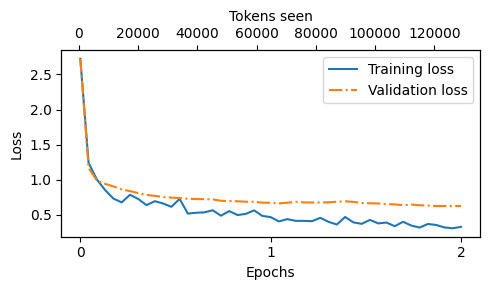

In [30]:
from previous_chapters import plot_losses

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))

plot_losses(epochs_tensor, token_seen, train_losses, val_losses)